In [7]:
import sys

# Install KaggleHub in the same Python environment as this notebook
!{sys.executable} -m pip install kagglehub

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2/2 [kagglehub]


In [1]:
import kagglehub
import pandas as pd
import os

# Download the dataset
path = kagglehub.dataset_download(
    "asaniczka/uk-optimal-product-price-prediction"
)

# Show the downloaded files
print("Dataset folder:", path)
print(os.listdir(path))

100%|██████████| 117M/117M [00:24<00:00, 4.93MB/s] 

Extracting files...


Dataset folder: /Users/andreazaffe/.cache/kagglehub/datasets/asaniczka/uk-optimal-product-price-prediction/versions/3
['amz_uk_price_prediction_dataset.csv']


In [2]:
# Load the dataset from the downloaded folder
file_path = os.path.join(path, "amz_uk_price_prediction_dataset.csv")

df = pd.read_csv(file_path)

# Check the data
display(df.head())
print(df.shape)
print(df.columns.tolist())

,uid,asin,title,stars,reviews,price,isBestSeller,boughtInLastMonth,category
0,1,B09B96TG33,"Echo Dot (5th generation, 2022 release) | Big ...",4.7,15308,21.99,False,0,Hi-Fi Speakers
1,2,B01HTH3C8S,"Anker Soundcore mini, Super-Portable Bluetooth...",4.7,98099,23.99,True,0,Hi-Fi Speakers
2,3,B09B8YWXDF,"Echo Dot (5th generation, 2022 release) | Big ...",4.7,15308,21.99,False,0,Hi-Fi Speakers
3,4,B09B8T5VGV,"Echo Dot with clock (5th generation, 2022 rele...",4.7,7205,31.99,False,0,Hi-Fi Speakers
4,5,B09WX6QD65,Introducing Echo Pop | Full sound compact Wi-F...,4.6,1881,17.99,False,0,Hi-Fi Speakers


(2443651, 9)
['uid', 'asin', 'title', 'stars', 'reviews', 'price', 'isBestSeller', 'boughtInLastMonth', 'category']


In [3]:
# Inspect the dataset before cleaning
print("Shape:", df.shape)

display(df.head())

print("\nColumn names:")
print(df.columns.tolist())

print("\nData types and missing values:")
df.info()

print("\nMissing values per column:")
display(df.isna().sum().sort_values(ascending=False))

print("\nDuplicate rows:", df.duplicated().sum())

print("\nSummary of numerical columns:")
display(df.describe())

Shape: (2443651, 9)


,uid,asin,title,stars,reviews,price,isBestSeller,boughtInLastMonth,category
0,1,B09B96TG33,"Echo Dot (5th generation, 2022 release) | Big ...",4.7,15308,21.99,False,0,Hi-Fi Speakers
1,2,B01HTH3C8S,"Anker Soundcore mini, Super-Portable Bluetooth...",4.7,98099,23.99,True,0,Hi-Fi Speakers
2,3,B09B8YWXDF,"Echo Dot (5th generation, 2022 release) | Big ...",4.7,15308,21.99,False,0,Hi-Fi Speakers
3,4,B09B8T5VGV,"Echo Dot with clock (5th generation, 2022 rele...",4.7,7205,31.99,False,0,Hi-Fi Speakers
4,5,B09WX6QD65,Introducing Echo Pop | Full sound compact Wi-F...,4.6,1881,17.99,False,0,Hi-Fi Speakers



Column names:
['uid', 'asin', 'title', 'stars', 'reviews', 'price', 'isBestSeller', 'boughtInLastMonth', 'category']

Data types and missing values:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2443651 entries, 0 to 2443650
Data columns (total 9 columns):
 #   Column             Dtype  
---  ------             -----  
 0   uid                int64  
 1   asin               object 
 2   title              object 
 3   stars              float64
 4   reviews            int64  
 5   price              float64
 6   isBestSeller       bool   
 7   boughtInLastMonth  int64  
 8   category           object 
dtypes: bool(1), float64(2), int64(3), object(3)
memory usage: 151.5+ MB

Missing values per column:


uid                  0
asin                 0
title                0
stars                0
reviews              0
price                0
isBestSeller         0
boughtInLastMonth    0
category             0
dtype: int64


Duplicate rows: 0

Summary of numerical columns:


,uid,stars,reviews,price,boughtInLastMonth
count,2.443651e+06,2.443651e+06,2.443651e+06,2.443651e+06,2.443651e+06
mean,1.370545e+06,2.152836e+00,4.806278e+02,8.924381e+01,2.589699e+01
std,8.160562e+05,2.194865e+00,5.944124e+03,3.456089e+02,2.404837e+02
min,1.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00
25%,6.589215e+05,0.000000e+00,0.000000e+00,9.990000e+00,0.000000e+00
50%,1.349029e+06,0.000000e+00,0.000000e+00,1.909000e+01,0.000000e+00
75%,2.060686e+06,4.400000e+00,5.900000e+01,4.599000e+01,0.000000e+00
max,2.828593e+06,5.000000e+00,1.356658e+06,1.000000e+05,5.000000e+04


## Dataset Inspection and Cleaning

The dataset was inspected by checking its dimensions, column names, data types and missing values.

No duplicate rows were found. The dataset contains the expected variables for this analysis, including category, price, rating, reviews and bestseller status. Missing values are limited and do not prevent the univariate analysis performed in this notebook.

The data is ready for exploratory data analysis.


# Part 1: Understanding Product Categories

### Business Question

What are the most popular product categories on Amazon UK, and how do they compare in terms of listing frequency?

In [7]:
# Part 1: Understanding Product Categories
# Question 1: Frequency Tables
#
# "Generate a frequency table for the product category."
# "Which are the top 5 most listed product categories?"

# Count the number of listings in each category
category_frequency = df["category"].value_counts()

print("Frequency table:")
display(category_frequency)

# Select the five most listed categories
top_5_categories = category_frequency.head(5)

print("Top 5 most listed product categories:")
display(top_5_categories)


Frequency table:


category
Sports & Outdoors                         836265
Beauty                                     19312
Handmade Clothing, Shoes & Accessories     19229
Bath & Body                                19092
Birthday Gifts                             18978
                                           ...  
Alexa Built-In Devices                       107
Motorbike Chassis                            107
Plugs                                        107
Smart Home Security & Lighting               104
Smart Speakers                                54
Name: count, Length: 296, dtype: int64

Top 5 most listed product categories:


category
Sports & Outdoors                         836265
Beauty                                     19312
Handmade Clothing, Shoes & Accessories     19229
Bath & Body                                19092
Birthday Gifts                             18978
Name: count, dtype: int64

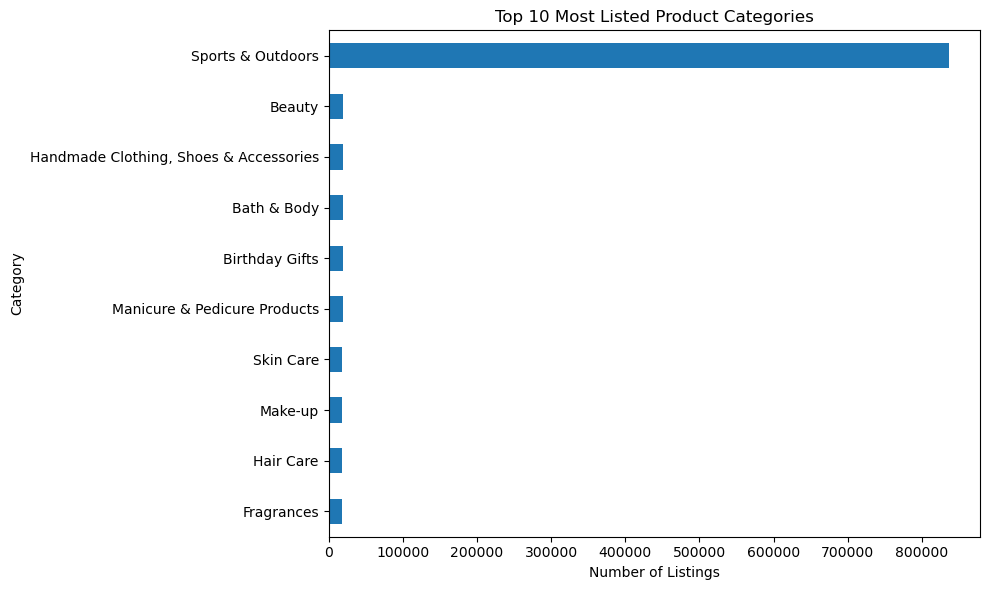

In [8]:
# Part 1: Understanding Product Categories
# Question 2a: Visualization

# "Display the distribution of products across different categories
# using a bar chart."

# Only the top 10 categories are shown because plotting every
# category would make the chart difficult to read.

import matplotlib.pyplot as plt

top_10_categories = category_frequency.head(10)

plt.figure(figsize=(10, 6))
top_10_categories.sort_values().plot(kind="barh")

plt.title("Top 10 Most Listed Product Categories")
plt.xlabel("Number of Listings")
plt.ylabel("Category")
plt.tight_layout()
plt.show()

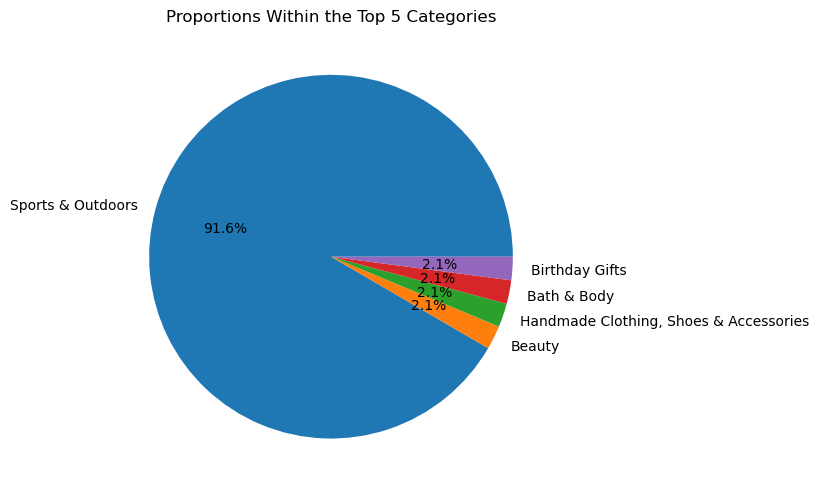

Sports & Outdoors represents 91.6% of the listings within the top five categories.


In [9]:
# Part 1: Understanding Product Categories
# Question 2b: Visualization

# "For a subset of top categories, visualize their proportions
# using a pie chart."
# "Does any category dominate the listings?"

plt.figure(figsize=(8, 8))

top_5_categories.plot(
    kind="pie",
    autopct="%1.1f%%",
    ylabel=""
)

plt.title("Proportions Within the Top 5 Categories")
plt.tight_layout()
plt.show()

# Calculate the share of the largest category within the top five
largest_category = top_5_categories.index[0]
largest_share = top_5_categories.iloc[0] / top_5_categories.sum() * 100

print(
    f"{largest_category} represents {largest_share:.1f}% "
    "of the listings within the top five categories."
)

In [10]:
# Part 2: Delving into Product Pricing
# Question 1: Measures of Centrality

# "Calculate the mean, median and mode for the price of products."
# "What is the average price point of products listed?"
# "How does the median price compare to the mean?"
# "What is the most common price?"

# Calculate the mean price
mean_price = df["price"].mean()

# Calculate the median price
median_price = df["price"].median()

# Calculate the mode price
mode_price = df["price"].mode()[0]

print(f"Mean price: £{mean_price:.2f}")
print(f"Median price: £{median_price:.2f}")
print(f"Mode price: £{mode_price:.2f}")

Mean price: £89.24
Median price: £19.09
Mode price: £9.99


In [12]:
# Part 2: Delving into Product Pricing
# Question 2: Measures of Dispersion

# "Calculate the variance, standard deviation and range for product prices."
# "How varied are the product prices?"
# "Are the prices spread out or concentrated around the average?"

# Calculate the variance
price_variance = df["price"].var()

# Calculate the standard deviation
price_std = df["price"].std()

# Calculate the minimum and maximum prices
minimum_price = df["price"].min()
maximum_price = df["price"].max()

# Calculate the price range
price_range = maximum_price - minimum_price

print(f"Price variance: {price_variance:.2f}")
print(f"Price standard deviation: £{price_std:.2f}")
print(f"Minimum price: £{minimum_price:.2f}")
print(f"Maximum price: £{maximum_price:.2f}")
print(f"Price range: £{price_range:.2f}")

Price variance: 119445.49
Price standard deviation: £345.61
Minimum price: £0.00
Maximum price: £100000.00
Price range: £100000.00


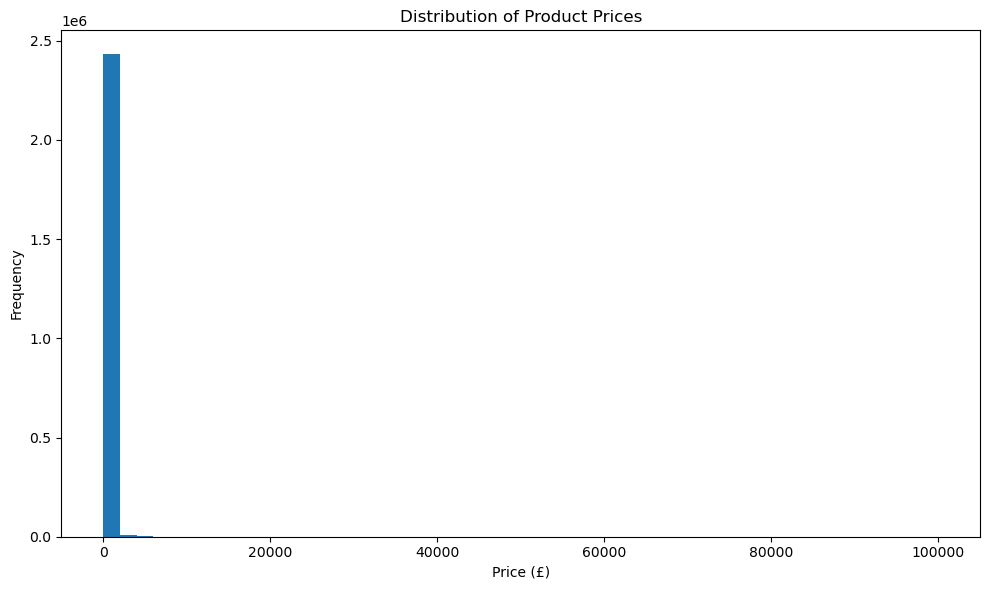

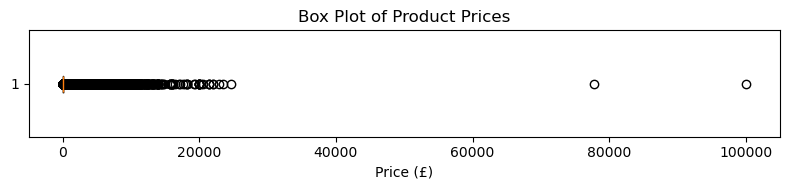

In [13]:
# Part 2: Delving into Product Pricing
# Question 3: Visualizations

# "Visualize the distribution of product prices using a histogram."
# "Evaluate if the distribution is symmetric or skewed."
# "Visualize the distribution of product prices using a box plot."
# "Are there any outliers? What can you say about the spread of prices?"

import matplotlib.pyplot as plt

# Histogram of product prices
plt.figure(figsize=(10, 6))
plt.hist(df["price"], bins=50)

plt.title("Distribution of Product Prices")
plt.xlabel("Price (£)")
plt.ylabel("Frequency")
plt.tight_layout()
plt.show()

# Box plot of product prices
plt.figure(figsize=(8, 2))
plt.boxplot(df["price"], vert=False)

plt.title("Box Plot of Product Prices")
plt.xlabel("Price (£)")
plt.tight_layout()
plt.show()